## Recomendación: Híbrido y comparación

- Ensamble ponderado de **filtrado colaborativo + contenido**

- **Validación** (2023 → 2024): se elige el peso `w` del híbrido

- **Test** (2023-2024 → 2025): se compara con los parámetros definidos

### Constantes

- `RANGO_W`: peso del filtrado colaborativo en el híbrido (0 = solo contenido, 1 = solo colaborativo)

- `TRAMOS`: tramos de actividad de la entidad (proveedores distintos en entrenamiento)

In [1]:
RANGO_W = [round(i / 10, 1) for i in range(11)]
TRAMOS = [0, 5, 20, 100, float("inf")]

### Detalle

- **Candidatos:** los top-`N_CAND` del colaborativo y de contenido para cada entidad

- **Normalización:** min-max dentro de cada entidad, para que ambos puntajes vayan de 0 a 1

- **Puntaje:** híbrido(e, p) = w · colaborativo + (1 − w) · contenido

- **Lista:** se reordena por el puntaje híbrido y se guardan los top-`N_CAND`

### Utilidades

In [2]:
NOTEBOOK = "e_hibrido"
%run ../funciones.ipynb
%run funciones.ipynb

Note: you may need to restart the kernel to use updated packages.


In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

Top-`N_CAND` por entidad que se guardó, en validación y en test

In [4]:
cfg = leer_config()
MODELOS = {"popularidad": "a", "regional": "a", "usuario": "b", "item": "b", "contenido_exacto": "c", "contenido": "c", "als": "d"}
ctx = {p: contexto(p, SENAL) for p in PARTICIONES}
recs = {(m, p): leer_recs(f"{m}_{p}") for m in MODELOS for p in PARTICIONES}
n_cat = {p: c["catalogo"].sum() for p, c in ctx.items()}
val = pd.DataFrame([{"modelo": m, "notebook": nb, **evaluar(recs[(m, "val")], ctx["val"]["pos"], n_cat["val"])} for m, nb in MODELOS.items()])
val.sort_values("ndcg@10", ascending=False)

,modelo,notebook,precision@10,recall@10,ndcg@10,hit@10,cobertura
1,regional,a,0.0516,0.1358,0.1118,0.3811,0.0605
6,als,d,0.0561,0.1234,0.1110,0.3925,0.4929
2,usuario,b,0.0588,0.1107,0.1066,0.3885,0.3946
3,item,b,0.0315,0.0600,0.0541,0.2165,0.7896
4,contenido_exacto,c,0.0278,0.0607,0.0526,0.2229,0.7320
5,contenido,c,0.0278,0.0607,0.0526,0.2224,0.7318
0,popularidad,a,0.0206,0.0305,0.0313,0.1676,0.0029


- En validación, la **popularidad regional** (0.112) y **ALS** (0.111) quedan arriba; user-user 0.106

- ALS es el mejor colaborativo en validación: es el que entra al híbrido

In [5]:
CF = val[val.modelo.isin(["usuario", "item", "als"])].set_index("modelo")["ndcg@10"].idxmax()
print("filtrado colaborativo del híbrido:", CF)

filtrado colaborativo del híbrido: als


---
### **1. Ensamble**

- **Colaborativo:** ALS (`recs_als`), el mejor colaborativo en validación

- **Contenido:** TF-IDF + LSA con búsqueda HNSW (`recs_contenido`)

- Cada modelo aporta sus `N_CAND` candidatos con puntaje min-max dentro de la entidad (0 a 1)

- Un candidato que un modelo no propuso recibe 0 de ese modelo

- Puntaje híbrido = w · colaborativo + (1 − w) · contenido

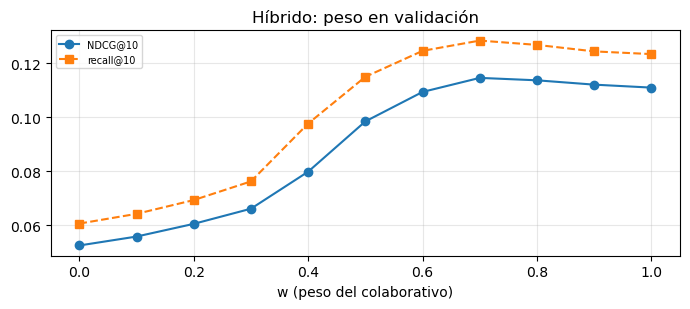

,w,precision@10,recall@10,ndcg@10,hit@10,cobertura
0,0.0,0.0278,0.0607,0.0526,0.2224,0.7318
1,0.1,0.0292,0.0643,0.0559,0.2323,0.7285
2,0.2,0.0316,0.0694,0.0606,0.2506,0.7247
3,0.3,0.0350,0.0763,0.0662,0.2748,0.7165
4,0.4,0.0429,0.0977,0.0799,0.3297,0.6933
5,0.5,0.0519,0.1150,0.0985,0.3737,0.6507
6,0.6,0.0574,0.1246,0.1094,0.3969,0.5983
7,0.7,0.0590,0.1284,0.1146,0.4073,0.5354
8,0.8,0.0582,0.1268,0.1137,0.4004,0.5115
9,0.9,0.0565,0.1244,0.1121,0.3915,0.4989


In [6]:
def hibrido(p, w, cf=CF):
    a = normalizar(recs[(cf, p)])[["entidad_idx", "proveedor_idx", "score"]].rename(columns={"score": "s_cf"})
    b = normalizar(recs[("contenido", p)])[["entidad_idx", "proveedor_idx", "score"]].rename(columns={"score": "s_co"})
    h = a.merge(b, on=["entidad_idx", "proveedor_idx"], how="outer").fillna(0)
    h["score"] = w * h.s_cf + (1 - w) * h.s_co
    h = h.sort_values(["entidad_idx", "score"], ascending=[True, False])
    h["rank"] = h.groupby("entidad_idx").cumcount() + 1
    return h[h["rank"] <= N_CAND][["entidad_idx", "rank", "proveedor_idx", "score", "s_cf", "s_co"]].reset_index(drop=True)

pesos = pd.DataFrame([{"w": w, **evaluar(hibrido("val", w), ctx["val"]["pos"], n_cat["val"])} for w in RANGO_W])
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(pesos.w, pesos["ndcg@10"], "o-", label="NDCG@10"); ax.plot(pesos.w, pesos["recall@10"], "s--", label="recall@10")
ax.set_xlabel("w (peso del colaborativo)"); ax.set_title("Híbrido: peso en validación"); ax.legend(fontsize=7)
mostrar_fig("peso_hibrido")
pesos

- Solo contenido (w = 0) da 0.053; solo ALS (w = 1) da 0.111

- **Máximo en w = 0.7: NDCG 0.115** y recall 0.128, por encima de ambos

- Se fija `W_HIBRIDO = 0.7`: el colaborativo ordena y el contenido aporta rubro

In [7]:
cfg["w_hibrido"] = W_HIBRIDO
cfg["cf_hibrido"] = CF
guardar_config(cfg)
for p in PARTICIONES:
    recs[("hibrido", p)] = hibrido(p, W_HIBRIDO)
    guardar_recs(recs[("hibrido", p)], f"hibrido_{p}")

---
### **2. Comparación en test (2025)**

Cada modelo se entrena en 2023-2024

| Modelo | Parámetros |
|---|---|
| Popularidad global | Sin parámetros: los proveedores con más entidades distintas en 2023-2024 |
| Popularidad regional | Sin parámetros: lo mismo, solo con proveedores de la región de la entidad |
| User-user / item-item | `SENAL` = binaria, `K_VEC` = 100 (users) / 400 (items) |
| Content (exacto / HNSW) | `MIN_DF` = 5, `MAX_DF` = 0.5, `DIM_SVD` = 512; HNSW con `M` = 32, `efSearch` = 256 |
| ALS | `RANK` = 64, `REG` = 1.0, `ALPHA` = 40, `ITER` = 15 |
| Híbrido | ALS + contenido (HNSW), `W_HIBRIDO` = 0.7 |

- `MIN_ENTIDADES` = 2, `K_EVAL` = 10 y `N_CAND` = 100. 

- Se evalúa si los proveedores recomendados reciben adjudicaciones de la entidad en 2025

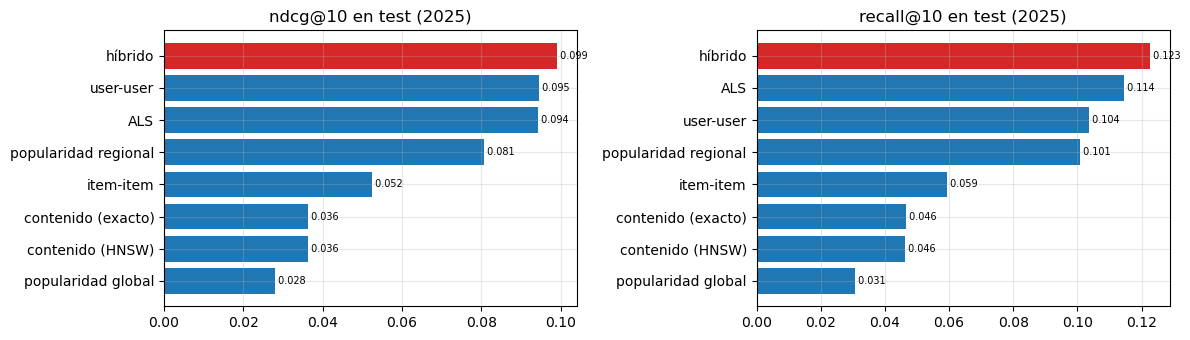

,modelo,precision@10,recall@10,ndcg@10,hit@10,cobertura
0,híbrido,0.0458,0.1226,0.0992,0.3527,0.3323
1,user-user,0.0439,0.1037,0.0946,0.3305,0.2219
2,ALS,0.0435,0.1144,0.0943,0.3385,0.2972
3,popularidad regional,0.0358,0.1008,0.0807,0.2860,0.0400
4,item-item,0.0265,0.0595,0.0525,0.2079,0.5984
5,contenido (exacto),0.0204,0.0465,0.0364,0.1728,0.5395
6,contenido (HNSW),0.0203,0.0464,0.0363,0.1723,0.5391
7,popularidad global,0.0157,0.0307,0.0281,0.1378,0.0019


In [8]:
NOMBRES = {"popularidad": "popularidad global", "regional": "popularidad regional", "usuario": "user-user", "item": "item-item",
           "contenido_exacto": "contenido (exacto)", "contenido": "contenido (HNSW)", "als": "ALS", "hibrido": "híbrido"}
test = pd.DataFrame([{"modelo": NOMBRES[m], **evaluar(recs[(m, "test")], ctx["test"]["pos"], n_cat["test"])} for m in NOMBRES])
test = test.sort_values("ndcg@10", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for i, met in enumerate(["ndcg@10", "recall@10"]):
    d = test.sort_values(met)
    ax[i].barh(d.modelo, d[met], color=["tab:red" if m == "híbrido" else "tab:blue" for m in d.modelo])
    for j, v in enumerate(d[met]):
        ax[i].text(v, j, f" {v:.3f}", va="center", fontsize=7)
    ax[i].set_title(f"{met} en test (2025)")
mostrar_fig("comparacion_test")
test

- **El híbrido es el mejor en test: NDCG@10 = 0.099**, recall@10 = 0.123 y hit@10 = 0.353

- Le siguen user-user (0.095) y ALS (0.094); popularidad regional queda en 0.081

- Contenido solo (0.036) está por debajo de la regional

- HNSW = exacto en calidad: la búsqueda aproximada no cuesta precisión

---
### **3. Por actividad de la entidad**

- Las entidades con pocas relaciones previas tienen poca señal colaborativa

- Se mide el NDCG@10 por tramo de proveedores distintos en entrenamiento

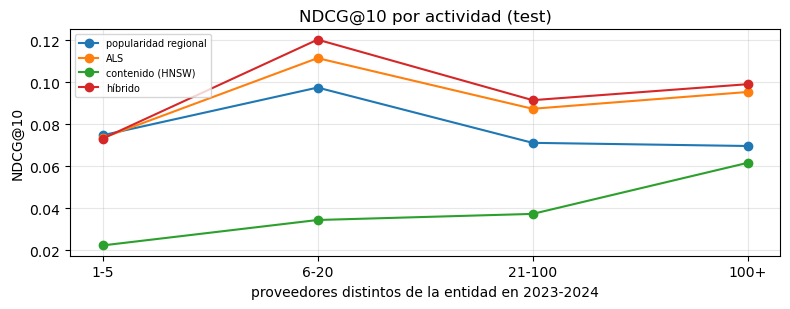

,ALS,contenido (HNSW),híbrido,popularidad regional,entidades
1-5,0.0735,0.0224,0.0732,0.0748,331
6-20,0.1115,0.0345,0.1203,0.0975,727
21-100,0.0874,0.0374,0.0915,0.0712,858
100+,0.0954,0.0617,0.0991,0.0697,196


In [9]:
c = ctx["test"]
grado = np.asarray(c["vistos"].sum(1)).ravel()
tramo = pd.cut(pd.Series(grado[c["entidades"]], index=c["entidades"]), TRAMOS, labels=["1-5", "6-20", "21-100", "100+"])
por_tramo = []
for t in tramo.cat.categories:
    pos_t = {e: c["pos"][e] for e in tramo.index[tramo == t]}
    for m in ["regional", CF, "contenido", "hibrido"]:
        por_tramo.append({"tramo": t, "entidades": len(pos_t), "modelo": NOMBRES[m],
                          "ndcg@10": evaluar(recs[(m, "test")][recs[(m, "test")].entidad_idx.isin(pos_t)], pos_t, n_cat["test"])["ndcg@10"]})
por_tramo = pd.DataFrame(por_tramo)
tabla_tramo = (por_tramo.pivot(index="tramo", columns="modelo", values="ndcg@10").join(por_tramo.groupby("tramo").entidades.first())
               .reindex(tramo.cat.categories))

fig, ax = plt.subplots(figsize=(8, 3.2))
for m in por_tramo.modelo.unique():
    d = por_tramo[por_tramo.modelo == m]
    ax.plot(d.tramo.astype(str), d["ndcg@10"], "o-", label=m)
ax.set_xlabel("proveedores distintos de la entidad en 2023-2024"); ax.set_ylabel("NDCG@10"); ax.set_title("NDCG@10 por actividad (test)")
ax.legend(fontsize=7)
mostrar_fig("ndcg_por_tramo")
tabla_tramo

- **Entidades con 1-5 proveedores (331):** todos rinden igual de poco (~0.07)

- **De 6 en adelante**, el híbrido supera a ALS en todos los tramos

- El contenido rinde mejor en las entidades grandes (0.062 en 100+): tienen más texto

---
### **4. Complementariedad**

- Se revisan los aciertos del híbrido en el top-10

- ¿Cuántos estaban también en el top-10 del colaborativo, del contenido, de ambos o de ninguno?

- Jaccard entre los top-10 del colaborativo y del contenido

In [10]:
top10 = {m: recs[(m, "test")][recs[(m, "test")]["rank"] <= K_EVAL].groupby("entidad_idx").proveedor_idx.apply(set) for m in [CF, "contenido", "hibrido"]}
origen = {"ambos": 0, "solo colaborativo": 0, "solo contenido": 0, "ninguno": 0}
for e, verdad in c["pos"].items():
    for x in top10["hibrido"].get(e, set()) & verdad:
        a, b = x in top10[CF].get(e, set()), x in top10["contenido"].get(e, set())
        origen["ambos" if a and b else "solo colaborativo" if a else "solo contenido" if b else "ninguno"] += 1
jac = np.mean([len(top10[CF].get(e, set()) & top10["contenido"].get(e, set())) / max(len(top10[CF].get(e, set()) | top10["contenido"].get(e, set())), 1)
               for e in c["pos"]])
complemento = pd.DataFrame([{"origen": k, "aciertos": v, "pct": round(100 * v / max(sum(origen.values()), 1), 1)} for k, v in origen.items()])
print(f"Jaccard medio top-10 colaborativo vs. contenido: {jac:.3f}")
complemento

Jaccard medio top-10 colaborativo vs. contenido: 0.037


,origen,aciertos,pct
0,ambos,94,9.7
1,solo colaborativo,723,74.7
2,solo contenido,92,9.5
3,ninguno,59,6.1


- Los top-10 de ALS y de contenido casi no se solapan (Jaccard 0.037)

- ALS y contenido proponen **proveedores distintos**

- De los aciertos del híbrido: 74.7% también estaban en el top-10 de ALS

- **9.5% solo en el de contenido** y 6.1% en ninguno

- El contenido aporta aciertos que el colaborativo no ve

#### a. Verificación

In [11]:
for p in PARTICIONES:
    r = leer_recs(f"hibrido_{p}")
    assert set(r.entidad_idx) == set(ctx[p]["pos"]) and r.groupby("entidad_idx").size().max() <= N_CAND, p
    assert ctx[p]["vistos"][r.entidad_idx.to_numpy(), r.proveedor_idx.to_numpy()].sum() == 0, p
print("híbrido: una lista por entidad, sin pares vistos | OK")

híbrido: una lista por entidad, sin pares vistos | OK


---
### **5. Escritura de resultados**

In [12]:
escritos = guardar_tablas({"modelos_validacion": val, "peso_hibrido": pesos, "comparacion_test": test,
                           "ndcg_por_tramo": por_tramo, "complementariedad": complemento})

Escrito en 03_Recomend/temp/e_hibrido/: modelos_validacion, peso_hibrido, comparacion_test, ndcg_por_tramo, complementariedad


#### a. Verificación

In [13]:
verificar_salidas(escritos)

OK: 5 tablas (parquet + json) | 3 figuras: comparacion_test, ndcg_por_tramo, peso_hibrido


---
### **6. Cerrar sesión**

In [14]:
spark.stop()